# Matching evaluation

Compares the matching methods of `matching_methods.ipynb` across comp
counts and targets:

- Section 2: every method at the same number of comps, 3 to 10, scored on
  every company.
- Section 3: ten chosen targets, one by one, and how consistent the
  methods are across them.

**Section 1 runs `matching_methods.ipynb` first** (its output hidden), so
the methods, comps and scoring are defined in one place. This notebook
uses its embeddings, comp sets, `score()` and `versus()`, and writes its
files to the same run folder. The same rules apply: financial fields are
read only in the valuation steps, after comps are fixed, and SIC codes are
for checking only.

## 1. Setup

In [1]:
%%capture methods_output
# runs every cell of the methods notebook in this kernel; its printed output is kept in methods_output
%run matching_methods.ipynb

In [2]:
# ---- settings -------------------------------------------------------------
TARGETS = [TARGET, "BV", "ROAD", "FIX", "BRO", "ADUS", "LOPE", "ODFL", "WING", "DXPE"]   # section 3
# ---------------------------------------------------------------------------
assert set(TARGETS) <= set(tickers), f"not matchable: {set(TARGETS) - set(tickers)}"
print(f"matching_methods.ipynb ran: {n} matchable companies, snapshot {SNAPSHOT}, run folder {RUN_DIR}")
print("comp sets from the methods notebook:", ", ".join(sets3))

matching_methods.ipynb ran: 535 matchable companies, snapshot company_list_v3, run folder C:\Users\micha\Qual2Cast\outputs-local\matching\20261019T080416Z
comp sets from the methods notebook: method 1 (cosine z), z >= 2.5, method 1 (cosine z), z >= 2, method 2 (mutual kNN), k = 20, method 2 (HDBSCAN), from eom, method 3 (agglomerative), complete linkage, method 3 (agglomerative), ward linkage, no matching (all other companies)


## 2. Every method at 3-10 comps

Each method's own rule in `matching_methods.ipynb` gives a different
number of comps (method 1 z ≥ 2: median 17; the tree: 7), and the number matters by itself: the median of
more comps is less noisy and closer to the all-company median. To compare
the methods on how well they *rank* candidates, each one here gives every
company exactly m comps, for m = 3, 4, … 10 (set before scoring):

| Method | Its m comps |
|---|---|
| Method 1 (cosine z) | the m most similar (z ranks a row the same way as cosine) |
| Method 2 (mutual kNN) | the m best by the worse of the two ranks (j's place in i's row, i's place in j's row), ties by cosine. The first m are the mutual neighbours at the smallest k that gives m |
| Method 2 (HDBSCAN, from eom) | cluster-mates at the eom level (`matching_methods.ipynb` 4.3, seed 0), most similar first; when the cluster has fewer than m others, the rest by the mutual kNN order. eom is the better-scoring start in its 4.4 |
| Method 3 (agglomerative), complete / ward | walk up the tree until the group has at least m others, then its m most similar |

Each count is scored like 3.5 and compared with method 1 at the same count
(paired bootstrap, `versus()` from `matching_methods.ipynb` 5.2).

In [3]:
COUNTS = range(3, 11)        # comps per company; set before scoring
CLUSTER_START = "eom"
M1_FIXED = "method 1 (cosine z)"

worse_rank = np.maximum(rank, rank.T)                     # rank: matching_methods 4.1, 0 = most similar
mutual_order = [nearest[i][np.argsort(worse_rank[i, nearest[i]], kind="stable")] for i in range(n)]

def fixed_cosine(m):
    return [[tickers[j] for j in nearest[i][:m]] for i in range(n)]

def fixed_mutual(m):
    return [[tickers[j] for j in mutual_order[i][:m]] for i in range(n)]

def fixed_cluster(m):
    lab, out = labels[CLUSTER_START], []
    for i in range(n):
        mates = [j for j in nearest[i] if lab[i] >= 0 and lab[j] == lab[i]]
        taken = set(mates)
        out.append([tickers[j] for j in (mates + [j for j in mutual_order[i] if j not in taken])[:m]])
    return out

def fixed_tree(method, m):
    _, members, parent = tree_parts[method]
    out = []
    for i in range(n):
        node = i
        while len(members[node]) - 1 < m:
            node = parent[node]
        group = set(members[node])
        out.append([tickers[j] for j in nearest[i] if j in group][:m])
    return out

FIXED_METHODS = {M1_FIXED: fixed_cosine, "method 2 (mutual kNN)": fixed_mutual,
                 "method 2 (HDBSCAN, from eom)": fixed_cluster,
                 **{M3_NAME.format(l): (lambda m, l=l: fixed_tree(l, m)) for l in LINKAGES}}
fixed_name = {(meth, m): f"{meth}, {m} comps" for meth in FIXED_METHODS for m in COUNTS}
fixed_sets = {fixed_name[meth, m]: f(m) for meth, f in FIXED_METHODS.items() for m in COUNTS}
assert all(len(c) == int(name.split(", ")[-1].split()[0]) for name, cs in fixed_sets.items() for c in cs)

fixed_summary, fixed_per_company = score({**fixed_sets, NO_MATCH: reference_sets[NO_MATCH]})
fixed_summary.to_csv(RUN_DIR / "fixed_counts_summary.csv")
fixed_per_company.round(4).to_csv(RUN_DIR / "fixed_counts_valuation.csv", index=False)
pd.DataFrame([{"comp set": name, "target": x, "rank": r + 1, "ticker": c}
              for name, cs in fixed_sets.items() for x, cl in zip(tickers, cs) for r, c in enumerate(cl)]
             ).to_csv(RUN_DIR / "fixed_counts_comps.csv", index=False)

vs_fixed = pd.concat([versus(fixed_per_company[fixed_per_company["comp set"].isin(
                          [fixed_name[meth, m] for meth in FIXED_METHODS])], ref=fixed_name[M1_FIXED, m])
                      for m in COUNTS])
vs_fixed.to_csv(RUN_DIR / "fixed_counts_vs_method1.csv")

def by_count(col):
    """Rows: methods; columns: comps per company."""
    return pd.DataFrame({m: [fixed_summary.loc[fixed_name[meth, m], col] for meth in FIXED_METHODS]
                         for m in COUNTS}, index=list(FIXED_METHODS)).rename_axis(columns="comps per company")

def diff_by_count(label):
    return pd.DataFrame({m: [f"{vs_fixed.loc[fixed_name[meth, m], f'{label}: difference']:+.2f} "
                             f"({vs_fixed.loc[fixed_name[meth, m], f'{label}: 95% interval']})"
                             for meth in list(FIXED_METHODS)[1:]] for m in COUNTS},
                        index=list(FIXED_METHODS)[1:]).rename_axis(columns="comps per company")

no_match_err = fixed_summary.loc[NO_MATCH, "median abs % error"]
print(f"Median abs % error (no matching: {no_match_err:.2f}):")
display(by_count("median abs % error").round(2))
print("Spearman(estimate, actual):")
display(by_count("Spearman(estimate, actual)").round(3))
print("Difference from method 1 at the same count, median abs % error (95% interval; lower is better):")
display(diff_by_count("median abs % error"))
print("Difference from method 1 at the same count, Spearman (95% interval; higher is better):")
display(diff_by_count("Spearman"))

Median abs % error (no matching: 34.62):


comps per company,3,4,5,6,7,8,9,10
method 1 (cosine z),36.41,36.31,35.47,34.45,35.97,36.64,36.45,35.14
method 2 (mutual kNN),36.59,35.12,34.33,34.11,35.42,35.70,35.97,35.25
"method 2 (HDBSCAN, from eom)",37.30,34.81,35.52,36.28,34.50,34.85,34.84,34.85
"method 3 (agglomerative), complete linkage",38.14,36.61,37.63,36.84,36.14,36.28,36.14,37.39
"method 3 (agglomerative), ward linkage",38.40,36.61,38.60,35.49,36.37,36.00,38.92,38.15


Spearman(estimate, actual):


comps per company,3,4,5,6,7,8,9,10
method 1 (cosine z),0.25,0.27,0.27,0.28,0.25,0.25,0.25,0.27
method 2 (mutual kNN),0.25,0.28,0.26,0.26,0.22,0.23,0.20,0.21
"method 2 (HDBSCAN, from eom)",0.28,0.29,0.26,0.26,0.26,0.29,0.26,0.25
"method 3 (agglomerative), complete linkage",0.26,0.27,0.24,0.21,0.20,0.15,0.19,0.17
"method 3 (agglomerative), ward linkage",0.31,0.32,0.26,0.28,0.29,0.25,0.20,0.18


Difference from method 1 at the same count, median abs % error (95% interval; lower is better):


comps per company,3,4,5,6,7,8,9,10
method 2 (mutual kNN),+0.00 (-3.07 to +3.32),-0.93 (-3.23 to +1.46),-0.52 (-2.88 to +2.07),-0.25 (-3.03 to +2.37),-0.16 (-3.02 to +2.66),-0.78 (-3.23 to +1.52),-0.92 (-3.36 to +1.29),+0.08 (-2.09 to +2.46)
"method 2 (HDBSCAN, from eom)",+0.73 (-2.11 to +3.79),-1.74 (-4.01 to +0.30),+0.18 (-2.54 to +3.37),+1.21 (-1.16 to +3.75),-0.85 (-3.89 to +2.28),-1.77 (-4.46 to +0.81),-2.02 (-4.49 to +0.23),-0.62 (-3.23 to +1.97)
"method 3 (agglomerative), complete linkage",+1.87 (-2.08 to +5.63),+0.10 (-3.52 to +3.28),+2.22 (-0.92 to +5.68),+2.09 (-0.88 to +4.77),+0.14 (-2.84 to +3.20),-0.28 (-3.15 to +2.39),-0.75 (-3.60 to +2.38),+1.89 (-0.78 to +4.70)
"method 3 (agglomerative), ward linkage",+2.02 (-1.16 to +5.35),+0.27 (-2.91 to +3.18),+3.78 (+0.79 to +7.53),+0.50 (-2.32 to +3.47),+0.29 (-2.92 to +3.63),-0.50 (-3.35 to +2.46),+1.83 (-0.79 to +4.50),+3.02 (+0.43 to +5.87)


Difference from method 1 at the same count, Spearman (95% interval; higher is better):


comps per company,3,4,5,6,7,8,9,10
method 2 (mutual kNN),+0.01 (-0.05 to +0.07),+0.01 (-0.05 to +0.07),-0.01 (-0.07 to +0.05),-0.03 (-0.09 to +0.03),-0.03 (-0.10 to +0.03),-0.02 (-0.09 to +0.04),-0.05 (-0.11 to +0.01),-0.06 (-0.12 to -0.00)
"method 2 (HDBSCAN, from eom)",+0.03 (-0.02 to +0.08),+0.02 (-0.04 to +0.08),-0.01 (-0.08 to +0.06),-0.03 (-0.09 to +0.04),+0.01 (-0.05 to +0.07),+0.04 (-0.02 to +0.10),+0.01 (-0.06 to +0.07),-0.02 (-0.08 to +0.04)
"method 3 (agglomerative), complete linkage",+0.01 (-0.06 to +0.09),-0.00 (-0.08 to +0.07),-0.04 (-0.12 to +0.04),-0.08 (-0.15 to -0.00),-0.05 (-0.12 to +0.03),-0.10 (-0.18 to -0.02),-0.06 (-0.14 to +0.02),-0.10 (-0.18 to -0.03)
"method 3 (agglomerative), ward linkage",+0.06 (-0.01 to +0.15),+0.05 (-0.03 to +0.13),-0.01 (-0.09 to +0.06),-0.00 (-0.08 to +0.07),+0.04 (-0.03 to +0.11),-0.01 (-0.08 to +0.07),-0.05 (-0.12 to +0.03),-0.09 (-0.16 to -0.01)


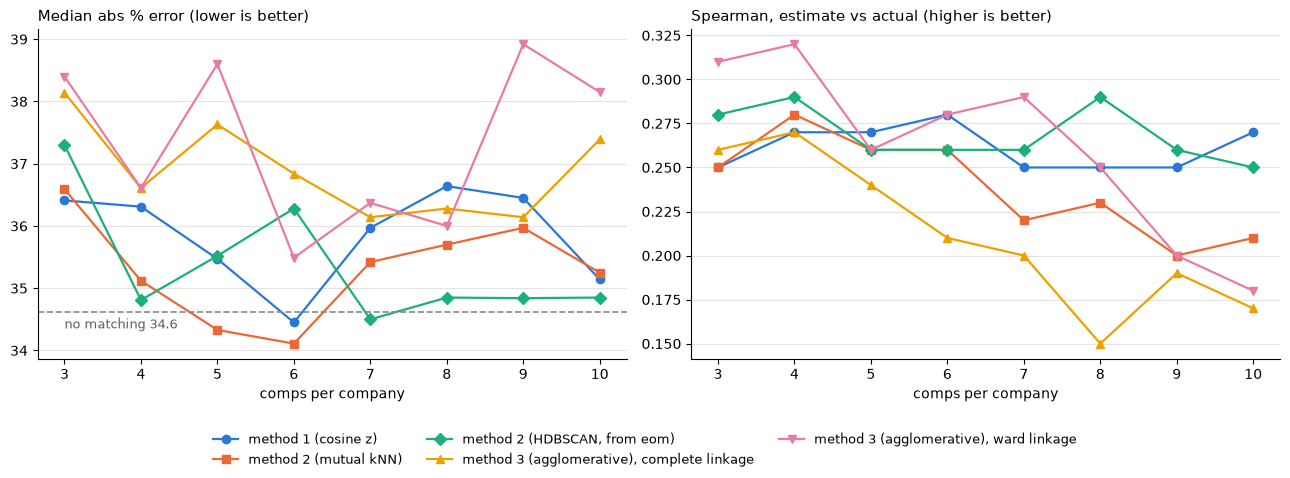

52647

In [4]:
# reference palette slots 1-5, validated (CVD and normal-vision separation pass); each line also has its own marker
COLOURS = dict(zip(FIXED_METHODS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
MARKERS = dict(zip(FIXED_METHODS, "osD^v"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col, title in zip(axes, ["median abs % error", "Spearman(estimate, actual)"],
                          ["Median abs % error (lower is better)", "Spearman, estimate vs actual (higher is better)"]):
    table = by_count(col)
    for meth in FIXED_METHODS:
        ax.plot(list(COUNTS), table.loc[meth], color=COLOURS[meth], marker=MARKERS[meth], lw=1.6, ms=6, label=meth)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("comps per company")
    ax.set_xticks(list(COUNTS))
    ax.grid(axis="y", color="#e4e3df", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].axhline(no_match_err, color="#8a8984", ls="--", lw=1.2)
axes[0].annotate(f"no matching {no_match_err:.1f}", (min(COUNTS), no_match_err), xytext=(0, -4),
                 textcoords="offset points", ha="left", va="top", fontsize=9, color="#5f5e5a")
handles, names_ = axes[0].get_legend_handles_labels()
fig.legend(handles, names_, loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig(RUN_DIR / "fixed_counts.png", dpi=150)
plt.show()

info = json.loads((RUN_DIR / "run_info.json").read_text(encoding="utf-8"))
info["fixed_counts"] = {"counts": list(COUNTS), "methods": list(FIXED_METHODS), "cluster_start": CLUSTER_START,
                        "reference": M1_FIXED, "summary": fixed_summary.reset_index().to_dict("records"),
                        "vs_method_1": vs_fixed.reset_index().to_dict("records")}
(RUN_DIR / "run_info.json").write_text(json.dumps(info, indent=2, default=str), encoding="utf-8")

## 3. Ten targets

`matching_methods.ipynb` 3.5 and section 2 here average over every company. Here are ten targets, one by
one, to see whether a method gives sensible comps across different kinds of
business. Each method uses its own rule (as in `matching_methods.ipynb` 5.2). The comps are listed
most similar first, so they can be checked against the companies' pages
(`universe_text.csv` has their URLs).

| Target | Why it's here |
|---|---|
| PCTY, Paylocity | The walk-through target in `matching_methods.ipynb` (payroll / HR software) |
| BV, BrightView | Aziz's landscaping example. The only landscaper in the list, so it tests whether a method knows it has no good matches |
| ROAD, Construction Partners | Road paving, with clear peers (Granite, Sterling): does a method separate civil construction from other contractors? |
| FIX, Comfort Systems | Mechanical / electrical contractor, with clear peers (Limbach, IES). With ROAD: are two kinds of contractor told apart? |
| BRO, Brown & Brown | Insurance broker with many direct peers (Gallagher, Ryan, Baldwin). An easy check, and a classic PE roll-up sector |
| ADUS, Addus HomeCare | Home health care: one direct peer (Aveanna) plus adjacent care providers |
| LOPE, Grand Canyon Education | For-profit education with clear peers (Strategic Education, Perdoceo, APEI), in a sector unlike the others |
| ODFL, Old Dominion | Trucking: a less-than-truckload carrier (like XPO) vs full-truckload carriers (Heartland, Marten), a finer distinction |
| WING, Wingstop | Franchised restaurants. Its multiple is far above its peers', a stress test for the valuation |
| DXPE, DXP Enterprises | Industrial distribution: do distributors come out as a group? |

The peers named above come from how the targets were chosen. They're
context for reading the comps, not labels the notebook scores.

In [5]:
industry = dict(zip(tickers, universe.target_primary_sic_industry))
target_rows = []
for x in TARGETS:
    i = pos[x]
    for name, cs in sets3.items():
        c = cs[i]
        target_rows.append({"target": x, "comp set": name, "comps": len(c),
                            "comps, most similar first": "(all other companies)" if name == NO_MATCH else
                                ", ".join(c[:12]) + (f", … (+{len(c) - 12})" if len(c) > 12 else ""),
                            "comps (all)": "" if name == NO_MATCH else " ".join(c)})
targets = (pd.DataFrame(target_rows)
           .merge(valuation_all_companies_t.drop(columns="comps"), on=["target", "comp set"], validate="one_to_one"))
targets.round(4).to_csv(RUN_DIR / "targets_comps.csv", index=False)

for x in TARGETS:
    i = pos[x]
    print(f"\n{x}  {universe.target_company_name[i]} | SIC {sic4[i]} {industry[x]} | actual EV/EBITDA {actual_all[i]:.2f}")
    display(targets[targets.target == x].set_index("comp set")
            [["comps", "comps, most similar first", "estimate", "error %"]].round(2))


PCTY  Paylocity Holding Corporation | SIC 7370 Computer Programming, Data Processing, And Other Computer Related Services | actual EV/EBITDA 22.13


,comps,"comps, most similar first",estimate,error %
comp set,,,,
"method 1 (cosine z), z >= 2.5",6,"PAYC, ADP, ASUR, BBSI, INTU, RPAY",14.87,-32.78
"method 1 (cosine z), z >= 2",14,"PAYC, ADP, ASUR, BBSI, INTU, RPAY, HURN, UPLD, KFY, FA, HQI, CSGS, … (+2)",13.54,-38.83
"method 2 (mutual kNN), k = 20",12,"PAYC, ADP, ASUR, BBSI, INTU, RPAY, KFY, FA, HQI, DBX, ALIT, PRTH",11.82,-46.56
"method 2 (HDBSCAN), from eom",7,"PAYC, ADP, ASUR, BBSI, FA, HQI, ALIT",14.38,-35.02
"method 3 (agglomerative), complete linkage",6,"PAYC, ADP, ASUR, BBSI, DBX, BLKB",13.05,-41.02
"method 3 (agglomerative), ward linkage",10,"PAYC, ADP, ASUR, BBSI, FA, AJG, ALIT, CRVL, CCC, HQY",18.14,-18.00
no matching (all other companies),534,(all other companies),10.84,-50.99



BV  BrightView Holdings, Inc. | SIC 0700 Agricultural Services | actual EV/EBITDA 6.68


,comps,"comps, most similar first",estimate,error %
comp set,,,,
"method 1 (cosine z), z >= 2.5",4,"TTC, GRBK, FOR, BDN",10.84,62.22
"method 1 (cosine z), z >= 2",14,"TTC, GRBK, FOR, BDN, STRL, TMHC, KBH, NPKI, ROAD, LTC, CDNL, QXO, … (+2)",13.22,97.91
"method 2 (mutual kNN), k = 20",5,"TTC, GRBK, FOR, NPKI, RYN",7.78,16.51
"method 2 (HDBSCAN), from eom",12,"GRBK, FOR, TMHC, KBH, DFH, CCS, ANGI, DHI, MTH, NVR, STC, SDHC",8.22,23.11
"method 3 (agglomerative), complete linkage",9,"FOR, NPKI, QXO, RYN, BOOM, BCC, AWI, OC, CSL",7.78,16.51
"method 3 (agglomerative), ward linkage",11,"FOR, STRL, NPKI, ROAD, CDNL, RYN, SMID, GVA, MCEM, BCC, BBCP",9.49,42.04
no matching (all other companies),534,(all other companies),10.89,62.94



ROAD  Construction Partners, Inc. | SIC 1600 Heavy Construction Other Than Building Construction Contractors | actual EV/EBITDA 16.46


...

,comps,"comps, most similar first",estimate,error %
comp set,,,,
"method 1 (cosine z), z >= 2.5",6,"XPO, JBHT, PAL, OPLN, EXPD, MRTN",12.56,-32.11
"method 1 (cosine z), z >= 2",18,"XPO, JBHT, PAL, OPLN, EXPD, MRTN, TRN, HTLD, DSGR, RAIL, GCT, DXPE, … (+6)",10.17,-45.01
"method 2 (mutual kNN), k = 20",10,"XPO, JBHT, PAL, OPLN, EXPD, MRTN, TRN, HTLD, PBI, PANL",11.31,-38.85
"method 2 (HDBSCAN), from eom",20,"XPO, JBHT, PAL, OPLN, EXPD, MRTN, TRN, HTLD, DSGR, RAIL, GCT, PBI, … (+8)",12.43,-32.79
"method 3 (agglomerative), complete linkage",8,"XPO, JBHT, PAL, EXPD, MRTN, TRN, HTLD, RAIL",10.97,-40.69
"method 3 (agglomerative), ward linkage",5,"XPO, JBHT, PAL, MRTN, HTLD",9.53,-48.49
no matching (all other companies),534,(all other companies),10.84,-41.36



WING  Wingstop Inc. | SIC 5812 Eating Places | actual EV/EBITDA 37.20


,comps,"comps, most similar first",estimate,error %
comp set,,,,
"method 1 (cosine z), z >= 2.5",8,"WEN, MKC, TXRH, BGS, SMPL, STKS, HRL, BROS",10.33,-72.23
"method 1 (cosine z), z >= 2",20,"WEN, MKC, TXRH, BGS, SMPL, STKS, HRL, BROS, BDL, REYN, TRIP, MRMD, … (+8)",8.52,-77.09
"method 2 (mutual kNN), k = 20",8,"WEN, MKC, TXRH, STKS, BROS, BDL, TAP, MGPI",8.11,-78.21
"method 2 (HDBSCAN), from eom",23,"WEN, MKC, TXRH, BGS, SMPL, STKS, HRL, BROS, SENE.A, TAP, MGPI, FIZZ, … (+11)",10.43,-71.98
"method 3 (agglomerative), complete linkage",7,"WEN, TXRH, STKS, BROS, BDL, TRIP, ABNB",10.24,-72.49
"method 3 (agglomerative), ward linkage",7,"WEN, TXRH, STKS, BROS, BDL, TRIP, ABNB",10.24,-72.49
no matching (all other companies),534,(all other companies),10.84,-70.85



DXPE  DXP Enterprises, Inc. | SIC 5080 Machinery, Equipment, And Supplies | actual EV/EBITDA 9.91


,comps,"comps, most similar first",estimate,error %
comp set,,,,
"method 1 (cosine z), z >= 2.5",3,"SPXC, ITT, CR",21.69,118.85
"method 1 (cosine z), z >= 2",8,"SPXC, ITT, CR, CSW, DSGR, NGS, TISI, WFRD",14.14,42.63
"method 2 (mutual kNN), k = 20",20,"SPXC, ITT, CR, CSW, DSGR, NGS, TISI, WFRD, POWL, FLS, PRLB, HEI, … (+8)",12.72,28.37
"method 2 (HDBSCAN), from eom",6,"SPXC, FIX, HDSN, AAON, THR, LII",17.95,81.07
"method 3 (agglomerative), complete linkage",9,"CR, TISI, RCMT, FSTR, EXPO, LGN, TIC, LMB, J",13.83,39.52
"method 3 (agglomerative), ward linkage",6,"ITT, CR, FLS, GRC, FTAI, PSIX",15.43,55.68
no matching (all other companies),534,(all other companies),10.89,9.84


### 3.1 Across the ten targets

Each target's % error under each method's own rule, then the same over the
ten targets at every fixed count from section 2. Ten companies is too few to
rank methods; this shows whether a method's comps behave the same way
across kinds of business or fail on some.

In [6]:
err = targets.pivot(index="target", columns="comp set", values="error %").reindex(index=TARGETS, columns=list(sets3))
no_match_abs = err[NO_MATCH].abs()
summary_rows = pd.DataFrame({"median abs % error (10 targets)": err.abs().median(),
                             "targets within 25%": (err.abs() <= 25).sum(),
                             "targets closer than no matching": (err.abs().lt(no_match_abs, axis=0)).sum()}).T
summary_rows.loc["targets closer than no matching", NO_MATCH] = np.nan
print("% error per target (estimate vs actual), each method's own rule:")
display(pd.concat([err.round(1), summary_rows.round(1)]).astype(object).where(lambda d: d.notna(), ""))

tf = fixed_per_company[fixed_per_company.target.isin(TARGETS)].copy()
tf["abs error %"] = tf["error %"].abs()
tf_med = tf.groupby("comp set")["abs error %"].median()
print("Median abs % error over the 10 targets, at each fixed count "
      f"(no matching: {err[NO_MATCH].abs().median():.1f}):")
display(pd.DataFrame({m: [tf_med[fixed_name[meth, m]] for meth in FIXED_METHODS] for m in COUNTS},
                     index=list(FIXED_METHODS)).rename_axis(columns="comps per company").round(1))
tf.round(4).to_csv(RUN_DIR / "targets_fixed_counts.csv", index=False)

info = json.loads((RUN_DIR / "run_info.json").read_text(encoding="utf-8"))
info["targets"] = {"targets": TARGETS, "error_pct": err.round(2).reset_index().to_dict("records"),
                   "summary": summary_rows.round(2).reset_index().to_dict("records")}
(RUN_DIR / "run_info.json").write_text(json.dumps(info, indent=2, default=str), encoding="utf-8")
print("saved:", sorted(p.name for p in RUN_DIR.iterdir()))

% error per target (estimate vs actual), each method's own rule:


comp set,"method 1 (cosine z), z >= 2.5","method 1 (cosine z), z >= 2","method 2 (mutual kNN), k = 20","method 2 (HDBSCAN), from eom","method 3 (agglomerative), complete linkage","method 3 (agglomerative), ward linkage",no matching (all other companies)
PCTY,-32.8,-38.8,-46.6,-35.0,-41.0,-18.0,-51.0
BV,62.2,97.9,16.5,23.1,16.5,42.0,62.9
ROAD,-29.3,-37.1,-37.6,-29.6,-35.7,-35.7,-34.1
FIX,-37.8,-33.3,-37.9,-42.3,-15.2,-15.2,-52.5
BRO,-42.6,-42.6,-41.9,-42.9,-37.3,-37.3,-38.8
ADUS,-21.0,-11.5,-23.9,-13.7,-8.4,-23.9,-9.7
LOPE,-38.1,-38.1,-37.7,-40.5,-37.7,-37.3,-13.3
ODFL,-32.1,-45.0,-38.8,-32.8,-40.7,-48.5,-41.4
WING,-72.2,-77.1,-78.2,-72.0,-72.5,-72.5,-70.8
DXPE,118.8,42.6,28.4,81.1,39.5,55.7,9.8


Median abs % error over the 10 targets, at each fixed count (no matching: 40.1):


comps per company,3,4,5,6,7,8,9,10
method 1 (cosine z),22.9,32.4,33.6,35.6,38.0,38.0,40.4,37.9
method 2 (mutual kNN),22.9,32.2,27.8,38.0,36.4,37.2,36.5,38.4
"method 2 (HDBSCAN, from eom)",27.8,30.7,36.8,36.3,36.8,35.7,36.5,38.8
"method 3 (agglomerative), complete linkage",25.8,30.4,34.2,35.0,36.0,38.3,38.4,40.4
"method 3 (agglomerative), ward linkage",27.8,31.0,40.4,38.4,38.0,38.4,39.8,40.3


saved: ['all_comps.csv', 'all_comps_clusters.csv', 'all_comps_mutual.csv', 'all_comps_tree.csv', 'cluster_stability.csv', 'cluster_tree.csv', 'cluster_tree.png', 'clusters.csv', 'comps_PCTY.csv', 'cosine_falloff_PCTY.png', 'excluded_companies.csv', 'fixed_counts.png', 'fixed_counts_comps.csv', 'fixed_counts_summary.csv', 'fixed_counts_valuation.csv', 'fixed_counts_vs_method1.csv', 'run_info.json', 'sic_check.csv', 'similarity_matrix.csv', 'targets_comps.csv', 'targets_fixed_counts.csv', 'tree_linkage_average.csv', 'tree_linkage_complete.csv', 'tree_linkage_ward.csv', 'tree_shape.csv', 'umap_embeddings.npy', 'universe_text.csv', 'valuation_PCTY.csv', 'valuation_all.csv', 'valuation_all_m2.csv', 'valuation_all_m2_clusters.csv', 'valuation_all_m3.csv', 'valuation_all_summary.csv', 'valuation_all_summary_m2.csv', 'valuation_all_summary_m2_clusters.csv', 'valuation_all_summary_m3.csv', 'valuation_comps_PCTY.csv', 'valuation_vs_method1_m3.csv']
